Test Accuracy: 100.00%
5-Fold CV Accuracy: 96.67%

Classification Report:
              precision    recall  f1-score   support

      Canned       1.00      1.00      1.00         3
       Dried       1.00      1.00      1.00         2
       Fresh       1.00      1.00      1.00         6
      Frozen       1.00      1.00      1.00         2
       Juice       1.00      1.00      1.00         3

    accuracy                           1.00        16
   macro avg       1.00      1.00      1.00        16
weighted avg       1.00      1.00      1.00        16


Confusion Matrix:
[[3 0 0 0 0]
 [0 2 0 0 0]
 [0 0 6 0 0]
 [0 0 0 2 0]
 [0 0 0 0 3]]


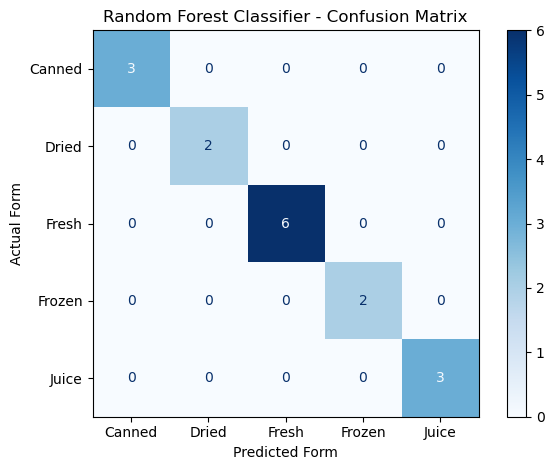

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.preprocessing import LabelEncoder

# 1. Load Cleaned Dataset
df = pd.read_csv('Fruit_Prices_2022_Cleaned.csv')

# 2. Encode Categorical Columns
le_target = LabelEncoder()
df['Form_encoded'] = le_target.fit_transform(df['Form'])

df['RetailPriceUnit_encoded'] = LabelEncoder().fit_transform(
    df['RetailPriceUnit']
)

df['CupEquivalentUnit_encoded'] = LabelEncoder().fit_transform(
    df['CupEquivalentUnit']
)

# 3. Features & Target Definition
feature_cols = [
    'RetailPrice',
    'Yield',
    'CupEquivalentSize',
    'CupEquivalentPrice',
    'RetailPriceUnit_encoded',
    'CupEquivalentUnit_encoded',
]

X = df[feature_cols]
y = df['Form_encoded']

# 4. Train-Test Split (75% Train, 25% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# 5. Model Training
rf_clf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_clf.fit(X_train, y_train)

# 6. Prediction & Evaluation
y_pred = rf_clf.predict(X_test)

print(f'Test Accuracy: {accuracy_score(y_test, y_pred):.2%}')

# 7. Cross-Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    rf_clf,
    X,
    y,
    cv=cv
)

print(f'5-Fold CV Accuracy: {cv_scores.mean():.2%}')

# 8. Classification Report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=le_target.classes_
    )
)

# 9. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

# 10. Plot Confusion Matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=le_target.classes_
)

disp.plot(
    cmap='Blues',
    values_format='d'
)

plt.title('Random Forest Classifier - Confusion Matrix')
plt.xlabel('Predicted Form')
plt.ylabel('Actual Form')
plt.tight_layout()
plt.show()
